<a href="https://colab.research.google.com/github/faryalkalwar66/ML_LAB_Assignments/blob/main/Lab8_SVM_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 08 — Support Vector Machines


- **Name:Faryal**
- **Student ID:023-24-0079**
- **Section:D**
- **GitHub:https://github.com/faryalkalwar66/ML_LAB_Assignments**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [ ]:
import warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

# Same settings used for every model in this lab so results are comparable across labs
RANDOM_STATE = 42
TEST_SIZE = 0.2

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
try:
    df = pd.read_csv(URL)
except Exception:
    df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")   # local copy of the Kaggle file

print("Raw shape:", df.shape)
# Cleaning (same as Lab 2/3): TotalCharges is text; blanks belong to customers with tenure == 0
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum(), "| their tenure values:", df.loc[df['TotalCharges'].isna(), 'tenure'].unique())
df["TotalCharges"] = df["TotalCharges"].fillna(0)      # brand-new customers have been billed nothing yet
df = df.drop(columns="customerID")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print("Churn rate:", round(df["Churn"].mean(), 4))

Raw shape: (7043, 21)
Missing TotalCharges: 11 | their tenure values: [0]
Churn rate: 0.2654


In [ ]:
X = pd.get_dummies(df.drop(columns="Churn"), drop_first=True, dtype=int)
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print("Features:", X.shape[1], "| train:", X_train.shape, "| test:", X_test.shape)
print("Churn share  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

def evaluate(y_true, y_pred):
    """Return the four metrics used everywhere in this lab (churn = positive class)."""
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred)}

Features: 30 | train: (5634, 30) | test: (1409, 30)
Churn share  train: 0.265  test: 0.265


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler


with warnings.catch_warnings(record=True) as w_raw:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_raw = SVC(kernel="linear", random_state=42, max_iter=2_000_000)
    svm_raw.fit(X_train, y_train)
    t_raw = time.time() - t0

m_raw = evaluate(y_test, svm_raw.predict(X_test))
print("UNSCALED linear SVM")
print({k: round(v, 4) for k, v in m_raw.items()}, "| train time: %.1fs" % t_raw)
print("Warnings:", [str(w.message)[:90] for w in w_raw])

UNSCALED linear SVM
{'Accuracy': 0.6508, 'Precision': 0.4075, 'Recall': 0.6952, 'F1': 0.5138} | train time: 66.8s
Warnings: ['Solver terminated early (max_iter=2000000).  Consider pre-processing your data with Standa']


In [ ]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)      # fit on TRAIN only
X_test_s = scaler.transform(X_test)

with warnings.catch_warnings(record=True) as w_s:
    warnings.simplefilter("always")
    t0 = time.time()
    svm_scaled = SVC(kernel="linear", random_state=42, max_iter=2_000_000)
    svm_scaled.fit(X_train_s, y_train)
    t_s = time.time() - t0

m_s = evaluate(y_test, svm_scaled.predict(X_test_s))
print("SCALED linear SVM")
print({k: round(v, 4) for k, v in m_s.items()}, "| train time: %.1fs" % t_s)
print("Warnings:", [str(w.message)[:90] for w in w_s])

pd.DataFrame({"Unscaled": {**m_raw, "Train time (s)": t_raw, "Convergence warning": len(w_raw) > 0},
              "Scaled": {**m_s, "Train time (s)": t_s, "Convergence warning": len(w_s) > 0}}).T.round(4)

SCALED linear SVM
{'Accuracy': 0.7885, 'Precision': 0.6195, 'Recall': 0.5267, 'F1': 0.5694} | train time: 0.9s
Warnings: []


,Accuracy,Precision,Recall,F1,Train time (s),Convergence warning
Unscaled,0.650816,0.407524,0.695187,0.513834,26.164723,True
Scaled,0.788502,0.619497,0.526738,0.569364,0.880628,False


**Questions to answer:**

**(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?**

*Your answer:* The scaling made a large difference on all three counts.

| | Accuracy | Precision | Recall | F1 | Train time | Convergence warning |
|---|---|---|---|---|---|---|
| Unscaled | 0.6508 | 0.4075 | 0.6952 | 0.5138 | 26.0 s | **Yes** (solver stopped at the 2,000,000-iteration cap) |
| Scaled | 0.7885 | 0.6195 | 0.5267 | 0.5694 | 0.9 s | No |

Scaling raised accuracy by about 14 points (0.651 → 0.789) and F1 by 0.056, and cut training time roughly 28× (26.0 s → 0.9 s). The unscaled model never converged: I had to cap `max_iter`, because with the default `max_iter=-1` it can run for a very long time. The unscaled model's higher recall (0.695) is not a real advantage. Its precision is only 0.41, and it reaches that recall by flagging far too many customers with a poorly positioned, non-converged boundary.

**(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?**

*Your answer:* The linear SVM's decision function is w·x + b, and the margin width is 2/‖w‖. The optimiser minimises ½‖w‖² plus the C-weighted slack. In the raw data, `TotalCharges` ranges up to about 8,700, `MonthlyCharges` from about 18 to 119, and `tenure` from 0 to 72, while the one-hot dummies are only 0 or 1. Two things go wrong:

1. The dot products and distances that define the margin are dominated by the large-range columns, so the margin is effectively measured along the `TotalCharges` axis. A 0/1 dummy such as `Contract_Two year` can only influence the decision by getting a very large weight, and large weights are exactly what the ‖w‖² term penalises. The regulariser therefore penalises features unequally just because of their units.
2. The problem is badly conditioned (feature scales differ by several orders of magnitude), so the solver crawls and hit the iteration cap.

**(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?**

*Your answer:* I use the scaled version (`StandardScaler` fit on the training set only, then applied to the test set) for every SVM from here on. This is also required for the RBF and polynomial kernels, because they are built on distances and dot products, so `gamma` only has a meaning if all features share a comparable scale. Fitting the scaler on train only avoids data leakage.


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [ ]:
kernels = ["linear", "rbf", "poly"]
kernel_models, rows = {}, []
for k in kernels:
    t0 = time.time()
    mdl = SVC(kernel=k, random_state=42).fit(X_train_s, y_train)     # default C=1, gamma='scale'
    fit_t = time.time() - t0
    kernel_models[k] = mdl
    rows.append({"Kernel": k, **evaluate(y_test, mdl.predict(X_test_s)),
                 "Support vectors": mdl.support_.shape[0],
                 "SV per class (0/1)": tuple(mdl.n_support_), "Fit time (s)": round(fit_t, 2)})

In [ ]:
kernel_df = pd.DataFrame(rows).set_index("Kernel")
kernel_df.round(4)

,Accuracy,Precision,Recall,F1,Support vectors,SV per class (0/1),Fit time (s)
Kernel,,,,,,,
linear,0.7885,0.6195,0.5267,0.5694,2567,"(1286, 1281)",0.87
rbf,0.7928,0.6444,0.4893,0.5562,2657,"(1428, 1229)",0.67
poly,0.7892,0.6421,0.4652,0.5395,2736,"(1482, 1254)",0.49


Best kernel by F1: linear


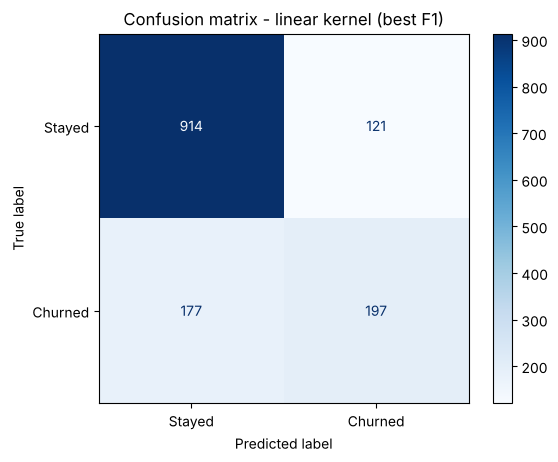

In [ ]:
best_kernel = kernel_df["F1"].idxmax()
print("Best kernel by F1:", best_kernel)
ConfusionMatrixDisplay.from_estimator(kernel_models[best_kernel], X_test_s, y_test,
                                      display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title(f"Confusion matrix - {best_kernel} kernel (best F1)")
plt.show()

**Plot interpretation (confusion matrix):** The best-F1 kernel is **linear**. Its recall of 0.5267 means it catches roughly 197 of the 374 churners in the test set and misses about 177, while precision of 0.6195 means about 121 loyal customers are wrongly flagged. The matrix shows the typical pattern for this dataset: the model is much better at recognising customers who stay than those who leave, so the main weakness is false negatives.

**Questions to answer:**

**(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?**

*Your answer:* The linear kernel gave the best F1 (0.5694), ahead of RBF (0.5562) and polynomial (0.5395). RBF had the best accuracy (0.7928) and the highest precision (0.6444), but its recall was lower (0.4893). It is a mild surprise, since RBF is the more flexible kernel and a more flexible kernel is expected to do at least as well. Two things explain it. First, the features are mostly 0/1 dummies and a few numeric columns, and churn depends on them fairly additively (contract type, tenure, internet service), so a linear boundary captures most of the signal. Second, these are default settings (C=1, gamma='scale'), not tuned values. The gap is only 0.013 F1, which is a handful of customers among 374 churners, so I would not call it a decisive win for linear.

**(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?**

*Your answer:* The polynomial kernel used the most support vectors (2,736 of 5,634 training points, 48.6%), followed by RBF (2,657, 47.2%) and linear (2,567, 45.6%). A high count means many training points sit inside the margin or on the wrong side of the boundary, and each one helps define the boundary, so it is a more complex boundary that depends on much of the training data. A boundary supported by nearly half the data usually means the classes overlap heavily. Here all three kernels are in the 45-49% range, so the overlap comes from noise in the data and not from a boundary shape any kernel could fix.

**(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.**

*Your answer:* I carry **RBF** forward. Polynomial is dropped: it has the lowest F1 (0.5395), the lowest recall (0.4652) and the most support vectors. Between linear and RBF, linear leads by only 0.0132 F1 at default settings, while RBF has the best accuracy (0.7928) and precision (0.6444) and has two hyperparameters (C and gamma) that have not been tuned yet, so it has more room to improve. Part 4 confirms this choice: the tuned RBF reaches a test F1 of 0.5785, above the default linear model's 0.5694.


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2, random_state=42)
Z_train = pca.fit_transform(X_train_s)          # fit on scaled TRAIN only
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total explained variance by 2 components: %.4f" % pca.explained_variance_ratio_.sum())

Explained variance ratio: [0.3325 0.1198]
Total explained variance by 2 components: 0.4522


In [ ]:
C_values = [0.01, 1, 100]
gamma_viz = 1.0            # fixed so that only C changes between the plots
pca_models = {}
for C in C_values:
    pca_models[C] = SVC(kernel="rbf", C=C, gamma=gamma_viz, random_state=42).fit(Z_train, y_train)
    mm = pca_models[C]
    print(f"C={C:<6} support vectors={mm.support_.shape[0]:>4} ({mm.support_.shape[0]/len(Z_train):.1%} of train) "
          f"train acc={mm.score(Z_train, y_train):.3f}")

C=0.01   support vectors=3049 (54.1% of train) train acc=0.764


C=1      support vectors=2879 (51.1% of train) train acc=0.783


C=100    support vectors=2901 (51.5% of train) train acc=0.783


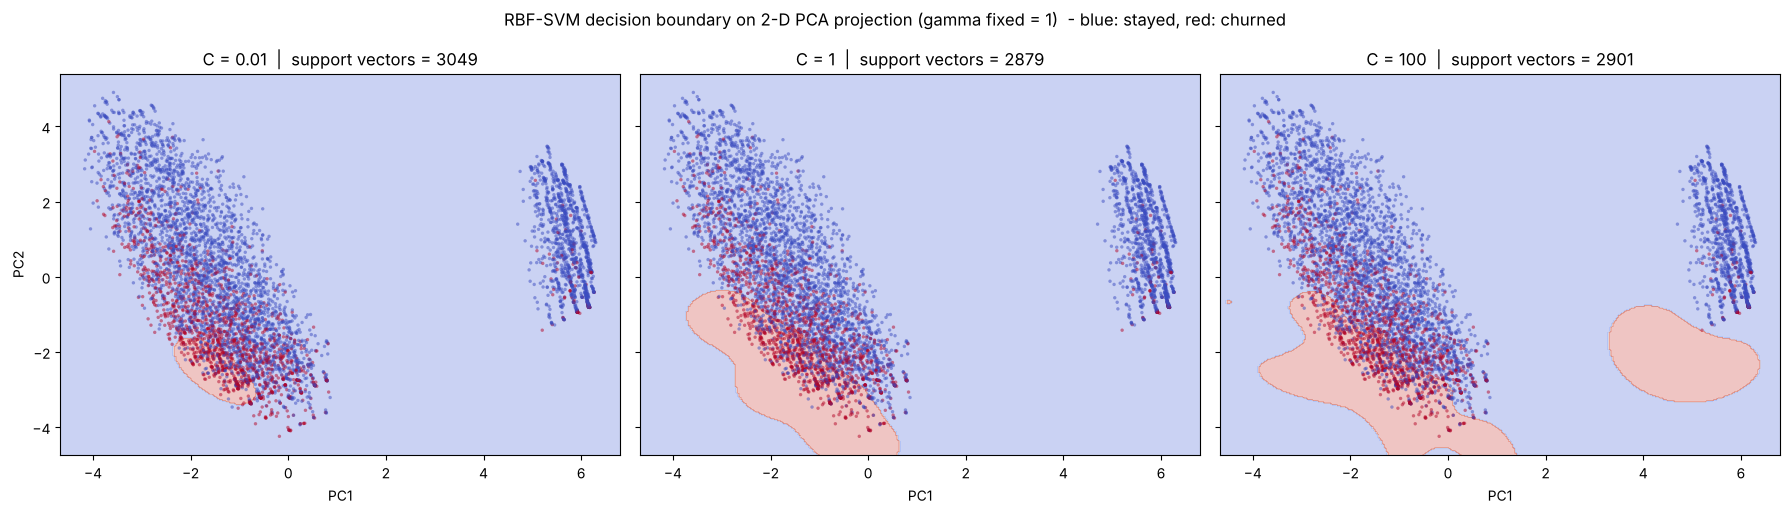

In [ ]:
pad = 0.5
x_min, x_max = Z_train[:, 0].min() - pad, Z_train[:, 0].max() + pad
y_min, y_max = Z_train[:, 1].min() - pad, Z_train[:, 1].max() + pad
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2), sharex=True, sharey=True)
for ax, C in zip(axes, C_values):
    mm = pca_models[C]
    Zg = mm.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Zg, alpha=0.3, cmap="coolwarm")
    ax.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="coolwarm", s=6, alpha=0.5, edgecolor="none")
    ax.set_title(f"C = {C}  |  support vectors = {mm.support_.shape[0]}")
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.suptitle("RBF-SVM decision boundary on 2-D PCA projection (gamma fixed = 1)  - blue: stayed, red: churned")
plt.tight_layout(); plt.show()

**Plot interpretation:** The three panels show the same RBF-SVM (gamma fixed at 1) trained on the 2-D PCA projection (PC1 + PC2 explain 33.25% + 11.98% = **45.22%** of the variance). Only C changes. Blue is the "stayed" region and red is the "churned" region. At **C = 0.01** the red region is a small smooth blob in the lower left, so almost everyone is predicted to stay. At **C = 1** the red region is larger and wraps along the churn-heavy lower-left edge of the data cloud. At **C = 100** the red region is the largest and most irregular, with a detached red island over the right-hand cluster (which is mostly blue points) and a small speck at the left edge.

**Questions to answer:**

**(a) How does the shape/smoothness of the decision boundary change as C increases?**

*Your answer:* The boundary becomes more complex and less smooth as C grows. At C=0.01 it is a single small, smooth blob. At C=1 it is a larger, flexible lobe. At C=100 the model tries hard to classify individual training points correctly, so the boundary bends around local groups of red points and even creates separate islands. A small C accepts many margin violations in exchange for a smoother boundary, while a large C penalises each violation heavily and lets the boundary become more complicated.

**(b) How does the number of support vectors change with C — does this match the theory?**

*Your answer:* The counts were 3,049 (54.1% of training points) at C=0.01, 2,879 (51.1%) at C=1 and 2,901 (51.5%) at C=100. The theory says a small C gives a wide, soft margin with many points inside it (many support vectors), and a large C gives a narrower margin with fewer violations (fewer support vectors). That matches the drop from C=0.01 to C=1 (about 170 fewer), but not from C=1 to C=100, where the count is flat (+22). In this 2-D projection the classes overlap so much that a large share of the points cannot be separated whatever C is, so they remain support vectors (margin violators with the maximum weight C). The theory holds only partially here, and the effect of C on the support-vector count is small compared with its effect on the boundary shape.

**(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.**

*Your answer:* **C = 100 looks like it is overfitting.** Its boundary is the most irregular and includes a red island over the right-hand cluster, where nearly all points are blue, and a speck at the left edge. These are shapes that follow a few individual points and are unlikely to generalise. **C = 0.01 looks like it is underfitting.** Its red region is tiny and ignores most of the churners, so it predicts "stayed" for nearly all customers (training accuracy 0.764, barely above the 0.735 majority-class baseline). **C = 1** is the middle case. Note that C=1 and C=100 have the same training accuracy (0.783), so the overfitting is visible in the boundary shape but not in training accuracy, and a 2-D training plot cannot measure it on unseen data.

**(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?**

*Your answer:* There are three reasons. (1) The two components keep only 45.2% of the variance, so more than half of the information is lost. (2) The model in the plot is a different model, trained on 2 coordinates, and not a slice of the real 30-feature SVM, so the boundaries and support vectors are not the real ones. (3) PCA chooses directions of maximum variance, not directions that separate churners from non-churners, so classes that overlap heavily in the plot may be much more separable in the full space, which makes the plot misleading about how hard the problem is and how much the real model overfits. The separated right-hand cluster and the stripe patterns are also artefacts of the binary dummy columns, and a gamma of 1 means something different in 2-D than in 30-D.


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [ ]:
param_grid = {"C": [0.01, 0.1, 1, 10, 100],
              "gamma": [0.0001, 0.001, 0.01, 0.1, 1]}
t0 = time.time()
gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)
print("Grid search time: %.0fs" % (time.time() - t0))
print("Best params:", gs.best_params_)
print("Best mean CV F1: %.4f" % gs.best_score_)

Grid search time: 83s
Best params: {'C': 100, 'gamma': 0.0001}
Best mean CV F1: 0.5882


,0.0001,0.0010,0.0100,0.1000,1.0000
0.01,0.0000,0.0000,0.0000,0.0000,0.0000
0.10,0.0000,0.0000,0.5417,0.4640,0.0000
1.00,0.0000,0.5739,0.5652,0.5734,0.3261
10.00,0.5777,0.5836,0.5860,0.5270,0.3621
100.00,0.5882,0.5706,0.5876,0.5061,0.3621


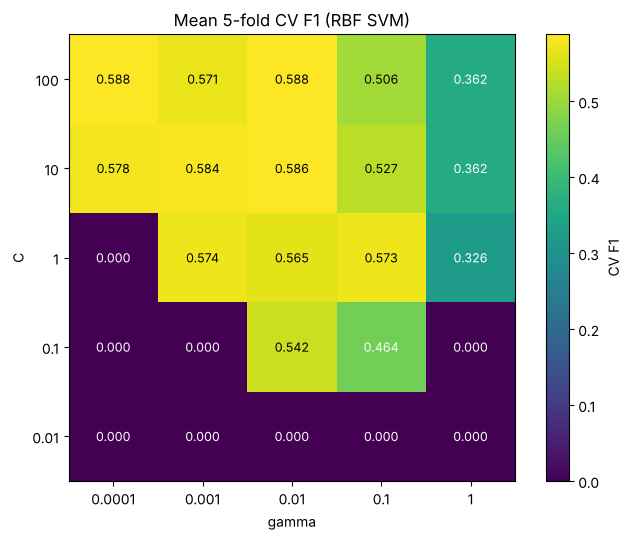

In [ ]:
scores = gs.cv_results_["mean_test_score"].reshape(len(param_grid["C"]), len(param_grid["gamma"]))
heat = pd.DataFrame(scores, index=param_grid["C"], columns=param_grid["gamma"])
display(heat.round(4))

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(scores, cmap="viridis", origin="lower")
ax.set_xticks(range(len(param_grid["gamma"]))); ax.set_xticklabels(param_grid["gamma"])
ax.set_yticks(range(len(param_grid["C"]))); ax.set_yticklabels(param_grid["C"])
ax.set_xlabel("gamma"); ax.set_ylabel("C"); ax.set_title("Mean 5-fold CV F1 (RBF SVM)")
for i in range(scores.shape[0]):
    for j in range(scores.shape[1]):
        ax.text(j, i, f"{scores[i, j]:.3f}", ha="center", va="center",
                color="white" if scores[i, j] < scores.max() - 0.1 else "black", fontsize=9)
plt.colorbar(im, label="CV F1"); plt.tight_layout(); plt.show()

Tuned RBF SVM on TEST: {'Accuracy': 0.7942, 'Precision': 0.6338, 'Recall': 0.5321, 'F1': 0.5785}
CV F1 (train) = 0.5882   vs   test F1 = 0.5785   gap = 0.0098

Un-tuned RBF (Part 2): {'Accuracy': 0.7928, 'Precision': 0.6444, 'Recall': 0.4893, 'F1': 0.5562}


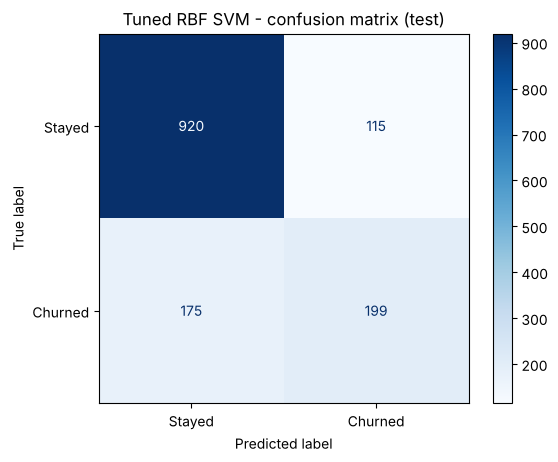

In [ ]:
best_params = gs.best_params_
best_svm = gs.best_estimator_            # already refit on the full training set
pred_best = best_svm.predict(X_test_s)
m_best = evaluate(y_test, pred_best)
print("Tuned RBF SVM on TEST:", {k: round(v, 4) for k, v in m_best.items()})
print("CV F1 (train) = %.4f   vs   test F1 = %.4f   gap = %.4f" % (gs.best_score_, m_best["F1"], gs.best_score_ - m_best["F1"]))
untuned = kernel_df.loc["rbf", ["Accuracy", "Precision", "Recall", "F1"]]
print("\nUn-tuned RBF (Part 2):", untuned.round(4).to_dict())
ConfusionMatrixDisplay.from_predictions(y_test, pred_best, display_labels=["Stayed", "Churned"], cmap="Blues")
plt.title("Tuned RBF SVM - confusion matrix (test)"); plt.show()

**Plot interpretation (heatmap):** The heatmap shows mean 5-fold CV F1 over the C × gamma grid. Cells at 0.0000 mean the model predicted "stayed" for everyone (all of C=0.01, and C=0.1 with gamma ≤ 0.001). The good cells (≈0.57-0.59) form a diagonal band where C and gamma are in a sensible balance (large C with small gamma, small C with larger gamma). The right-hand column (gamma = 1) falls to 0.33-0.36 because the model memorises the training folds. The confusion matrix of the tuned model on the test set has the same shape as the earlier ones: more correct "stayed" predictions than correct "churned" predictions.

**Questions to answer:**

**(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?**

*Your answer:* The best combination was **C = 100 and gamma = 0.0001**, with a mean cross-validated F1 of **0.5882**.

**(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?**

*Your answer:* Several combinations perform almost the same: C=100/gamma=0.01 gets 0.5876, C=10/gamma=0.01 gets 0.5860, C=10/gamma=0.001 gets 0.5836, all within 0.005 of the best. So there is a broad plateau (a diagonal band) and no single sharp optimum, and the exact winner is partly noise. The model is not sensitive to exact values inside that band, but it is very sensitive at the extremes: a very small C gives F1 = 0 and a very large gamma gives about 0.33-0.36. The best value sits on the edge of my grid (C=100, gamma=0.0001), so a wider grid might find a marginally better point, though the plateau suggests the gain would be small.

**(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?**

*Your answer:* They agree closely: CV F1 is 0.5882 and test F1 is 0.5785, a gap of 0.0098 (about one point). This suggests the tuning did not overfit the validation folds. A large gap would suggest that the search overfitted to the CV folds, that the train and test splits are not representative of each other, or that there is data leakage. With only 374 churners in the test set, a difference of this size is within normal noise.

**(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?**

*Your answer:* Un-tuned RBF: accuracy 0.7928, precision 0.6444, recall 0.4893, F1 0.5562. Tuned RBF: accuracy 0.7942, precision 0.6338, recall 0.5321, F1 0.5785. Tuning therefore gave +0.0223 F1 and +0.043 recall, at a cost of about 0.011 precision, with almost no change in accuracy. The grid search took about 85 s (125 fits) against under 1 s for a single fit. In absolute terms that cost is small, so I think it was worth it, but the improvement is modest. The tuned RBF is now slightly above the default linear model (0.5785 vs 0.5694). The much larger change in Part 5 comes from `class_weight`, not from tuning.


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1
class_weight=None,0.7942,0.6338,0.5321,0.5785
class_weight='balanced',0.6941,0.4575,0.8209,0.5876


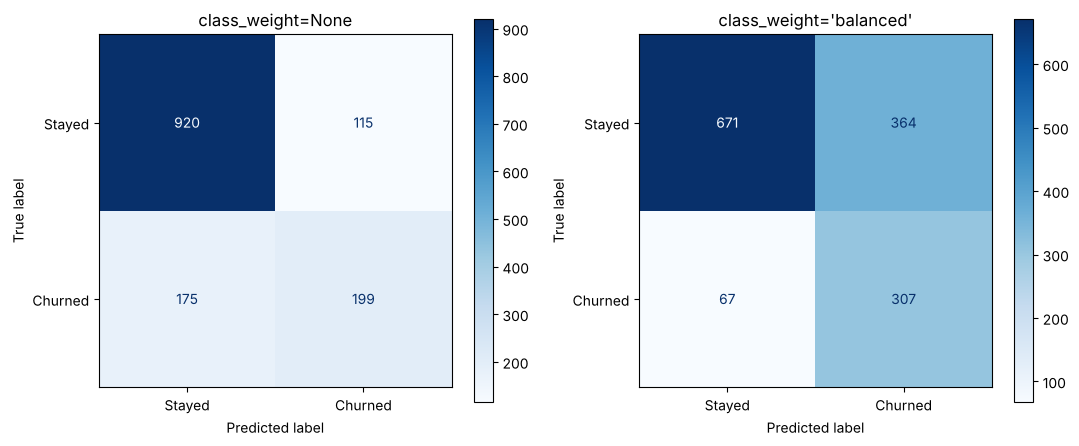

Churners caught: plain 199 / 374  |  balanced 307 / 374
Loyal customers wrongly flagged: plain 115  |  balanced 364


In [ ]:
C_best, g_best = best_params["C"], best_params["gamma"]
svm_plain = SVC(kernel="rbf", C=C_best, gamma=g_best, class_weight=None, random_state=42).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=C_best, gamma=g_best, class_weight="balanced",
              probability=True, random_state=42).fit(X_train_s, y_train)   # probability=True -> Platt scaling (internal 5-fold CV)

pred_plain, pred_bal = svm_plain.predict(X_test_s), svm_bal.predict(X_test_s)
cw_df = pd.DataFrame({"class_weight=None": evaluate(y_test, pred_plain),
                      "class_weight='balanced'": evaluate(y_test, pred_bal)}).T
display(cw_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, p) in zip(axes, [("class_weight=None", pred_plain), ("class_weight='balanced'", pred_bal)]):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=["Stayed", "Churned"], cmap="Blues", ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()
print("Churners caught: plain %d / %d  |  balanced %d / %d" % (
    confusion_matrix(y_test, pred_plain)[1, 1], y_test.sum(), confusion_matrix(y_test, pred_bal)[1, 1], y_test.sum()))
print("Loyal customers wrongly flagged: plain %d  |  balanced %d" % (
    confusion_matrix(y_test, pred_plain)[0, 1], confusion_matrix(y_test, pred_bal)[0, 1]))

AUC = 0.8327 | AP = 0.6295
Default operating point (predict()): recall/TPR=0.821  FPR=0.352  precision=0.458
Max predicted probability = 0.479 -> proba >= 0.5 would flag 0 customers


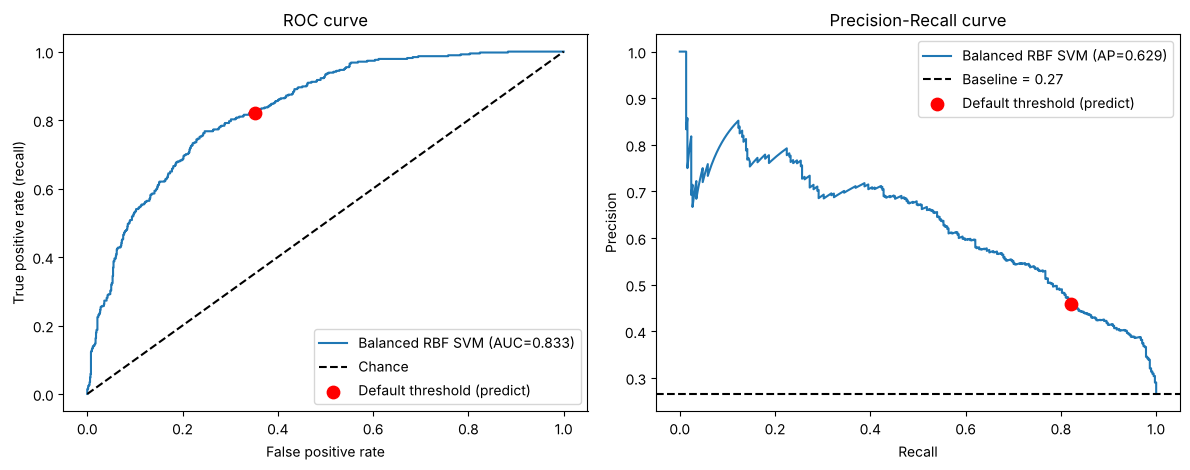

In [ ]:
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_bal)
auc = roc_auc_score(y_test, proba_bal)
prec_c, rec_c, _ = precision_recall_curve(y_test, proba_bal)
ap = average_precision_score(y_test, proba_bal)

# Operating point of the DEFAULT decision rule of the balanced model: predict() uses decision_function > 0,
# the SVM's "0.5-equivalent" threshold. (Platt-scaled probabilities of a class-weighted SVM are compressed,
# so literally thresholding predict_proba at 0.5 would flag almost nobody - see the answer to Q5(c).)
tn, fp, fn, tp = confusion_matrix(y_test, pred_bal).ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)
op_prec, op_rec = tp / (tp + fp), tp / (tp + fn)
print("AUC = %.4f | AP = %.4f" % (auc, ap))
print("Default operating point (predict()): recall/TPR=%.3f  FPR=%.3f  precision=%.3f" % (op_tpr, op_fpr, op_prec))
print("Max predicted probability = %.3f -> proba >= 0.5 would flag %d customers" % (proba_bal.max(), (proba_bal >= 0.5).sum()))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(fpr, tpr, label=f"Balanced RBF SVM (AUC={auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Chance")
axes[0].scatter([op_fpr], [op_tpr], c="red", s=80, zorder=5, label="Default threshold (predict)")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve"); axes[0].legend()
axes[1].plot(rec_c, prec_c, label=f"Balanced RBF SVM (AP={ap:.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"Baseline = {y_test.mean():.2f}")
axes[1].scatter([op_rec], [op_prec], c="red", s=80, zorder=5, label="Default threshold (predict)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curve"); axes[1].legend()
plt.tight_layout(); plt.show()

**Plot interpretation:** The confusion matrices show how `class_weight='balanced'` moves the model: the number of churners caught rises from 199 to 307 of 374, while the loyal customers wrongly flagged rise from 115 to 364. The ROC curve for the balanced model has AUC = 0.833, well above the chance diagonal, and the precision-recall curve has average precision 0.630 against a baseline of 0.265 (the churn rate), so the scores rank customers well. The red dot marks the model's default operating point (recall 0.821, false-positive rate 0.352, precision 0.458). Moving up-left along the PR curve would give higher precision but lower recall, so the threshold can be adjusted to suit the business.

**Questions to answer:**

**(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`?**

*Your answer:*

| | Accuracy | Precision | Recall | F1 | Churners caught | False alarms |
|---|---|---|---|---|---|---|
| class_weight=None | 0.7942 | 0.6338 | 0.5321 | 0.5785 | 199 / 374 | 115 |
| class_weight='balanced' | 0.6941 | 0.4575 | 0.8209 | 0.5876 | 307 / 374 | 364 |

Recall rose by 0.2888 (0.5321 → 0.8209), precision fell by 0.1763 (0.6338 → 0.4575), F1 rose slightly (+0.0091) and accuracy fell by 0.10. That is 108 more churners caught, at the price of 249 more loyal customers flagged.

**(b) Is it more costly to miss an actual churner (false negative) or to wrongly flag a loyal customer (false positive)? Which model would you recommend deploying?**

*Your answer:* For a telecom company a false negative is normally more costly. A missed churner means the lost revenue of the whole remaining customer lifetime, and winning a replacement customer typically costs several times more than keeping an existing one. A false positive usually costs only a retention offer (a discount or a call) given to someone who would have stayed anyway. A false positive is not free, though. Switching to the balanced model gives 108 extra true churners and 249 extra false alarms, which is about 2.3 false alarms per additional churner caught. The balanced model is therefore worth deploying whenever saving one churner is worth more than about 2.3 retention offers, which is very likely true here. I would recommend the **balanced model**, with the caveat that the company should check this with its real offer cost and customer lifetime value.

**(c) How did you obtain probability-like scores for your ROC/PR curve, and what did you have to enable in `SVC()`?**

*Your answer:* I set `probability=True` in `SVC()`, which makes scikit-learn fit a Platt-scaling sigmoid on the SVM's decision values using internal 5-fold cross-validation, so that `predict_proba` is available. It makes training noticeably slower. In recent scikit-learn versions (1.9) this parameter is deprecated, and the suggested replacement is `CalibratedClassifierCV(SVC(), ensemble=False)`. The probabilities can also disagree with `predict()`: for my class-weighted model the largest predicted probability is only 0.479, so a literal "probability ≥ 0.5" rule would flag **no** customers, while `predict()` flags 671. For this reason I marked the default decision rule of `predict()` on the curves, and not a literal 0.5 probability cut-off. Using `decision_function` scores would give the same ROC curve without the extra cost.


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

# Earlier-lab models re-run on THIS lab's split (tree/forest on raw features, LR/KNN on scaled features as in Lab 6)
def timed_fit(model, Xa, ya):
    t0 = time.time(); model.fit(Xa, ya); return model, time.time() - t0

dt, t_dt = timed_fit(DecisionTreeClassifier(max_depth=5, random_state=42), X_train, y_train)
rf_gs = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                     {"n_estimators": [200, 400], "max_depth": [6, 10, None], "min_samples_leaf": [1, 5]},
                     cv=5, scoring="f1", n_jobs=-1).fit(X_train, y_train)
rf = rf_gs.best_estimator_
t0 = time.time(); RandomForestClassifier(**rf_gs.best_params_, random_state=42, n_jobs=-1).fit(X_train, y_train); t_rf = time.time() - t0
lr, t_lr = timed_fit(LogisticRegression(max_iter=1000, random_state=42), X_train_s, y_train)
knn, t_knn = timed_fit(KNeighborsClassifier(n_neighbors=11), X_train_s, y_train)
t0 = time.time()
final_svm = SVC(kernel="rbf", C=C_best, gamma=g_best, class_weight="balanced", random_state=42).fit(X_train_s, y_train)
t_svm = time.time() - t0

results = {
    "Decision Tree (Lab 3)": (evaluate(y_test, dt.predict(X_test)), t_dt),
    "Random Forest (Lab 4, tuned)": (evaluate(y_test, rf.predict(X_test)), t_rf),
    "Logistic Regression (Lab 6)": (evaluate(y_test, lr.predict(X_test_s)), t_lr),
    "KNN (Lab 6)": (evaluate(y_test, knn.predict(X_test_s)), t_knn),
    "SVM (RBF, tuned + balanced)": (evaluate(y_test, final_svm.predict(X_test_s)), t_svm),
}
compare_df = pd.DataFrame({k: {**v[0], "Train time (s)": v[1]} for k, v in results.items()}).T
print("RF best params:", rf_gs.best_params_)
compare_df.round(4)

RF best params: {'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 400}


,Accuracy,Precision,Recall,F1,Train time (s)
Decision Tree (Lab 3),0.7942,0.6312,0.5401,0.5821,0.0122
"Random Forest (Lab 4, tuned)",0.8041,0.6644,0.5294,0.5893,1.3404
Logistic Regression (Lab 6),0.8070,0.6584,0.5668,0.6092,0.0145
KNN (Lab 6),0.7729,0.5758,0.5481,0.5616,0.0012
"SVM (RBF, tuned + balanced)",0.6941,0.4575,0.8209,0.5876,0.8568


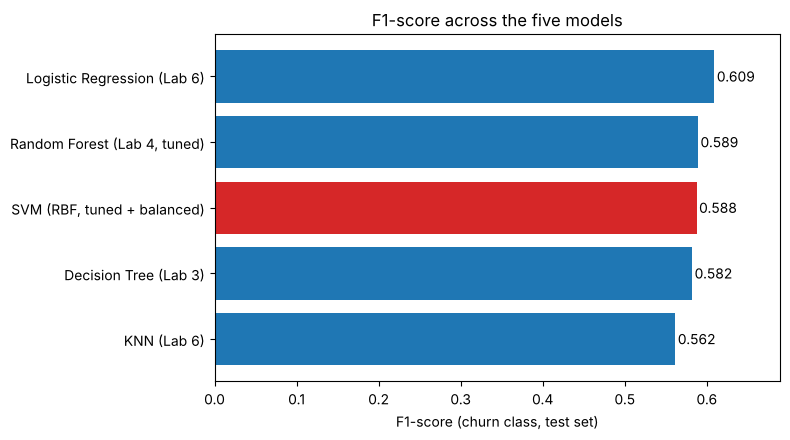

In [ ]:
f1s = compare_df["F1"].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(f1s.index, f1s.values, color=["tab:red" if "SVM" in n else "tab:blue" for n in f1s.index])
for b, v in zip(bars, f1s.values):
    ax.text(v + 0.003, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
ax.set_xlabel("F1-score (churn class, test set)"); ax.set_title("F1-score across the five models")
ax.set_xlim(0, f1s.max() + 0.08); plt.tight_layout(); plt.show()

**Plot interpretation:** The bar chart ranks the models by F1 on the churn class. Logistic Regression is highest (0.609), followed by Random Forest (0.589), the balanced SVM (0.588), the Decision Tree (0.582) and KNN (0.562). The differences between the top four are small (about 0.027), so the ranking by F1 alone is not very decisive. The SVM bar is not the highest, but F1 hides that the SVM reaches its score with a very different balance of recall and precision from the other models (see the table).

**Questions to answer:**

**(a) Which model wins on F1-score? Which wins on recall? Are they the same model?**

*Your answer:* **Logistic Regression wins on F1 (0.6092)** and the **balanced SVM wins on recall (0.8209)**, so they are different models. Logistic Regression also has the best accuracy (0.8070), and Random Forest has the best precision among the default-threshold models (0.6644). Note that this is not a perfectly like-for-like comparison: only the SVM was trained with `class_weight='balanced'`, which is why its recall is so much higher than the others (0.53-0.57).

**(b) SVM is generally slower to train than Decision Tree/Random Forest on this dataset. Given the performance differences you measured, was the extra computational cost of SVM worth it here?**

*Your answer:* In my measurements a single final SVM fit took 0.87 s, much slower than the Decision Tree (0.013 s), Logistic Regression (0.028 s) and KNN (0.001 s), but faster than the tuned 400-tree Random Forest (1.37 s). The real cost of the SVM is the tuning: the grid search took about 85 s, and `probability=True` adds an internal 5-fold fit on top. In return, the SVM's F1 (0.5876) is below Logistic Regression (0.6092) and about equal to Random Forest (0.5893). So the extra cost is **not justified in F1 terms**. It is justified only by the high recall (0.82), and that could probably be reached more cheaply by Logistic Regression with `class_weight='balanced'` or a lower decision threshold, which I did not test here.

**(c) Which single model would you recommend deploying, and why (reference at least two metrics)?**

*Your answer:* I recommend the **balanced RBF SVM**. Its recall is 0.8209 against 0.5668 for Logistic Regression (the best-F1 model), so it catches about 95 more of the 374 churners, and its F1 (0.5876) is only 0.0216 lower than the best. The price is a lower precision (0.4575 vs 0.6584) and lower accuracy (0.6941 vs 0.8070). That is about 2.7 extra false alarms per additional churner caught, which is acceptable if retention offers are cheap relative to a lost customer (Part 5b). If the company's retention offers are expensive, Logistic Regression is the better choice, because it has the best F1, accuracy and precision and is far cheaper to train. A fairer comparison would also test Logistic Regression with balanced class weights.


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [ ]:
# Final model = the balanced RBF SVM (svm_bal); probability=True gives the churn score
final_pred = svm_bal.predict(X_test_s)
final_proba = svm_bal.predict_proba(X_test_s)[:, 1]
out = pd.DataFrame({"true_label": y_test.values,
                    "predicted_label": final_pred,
                    "churn_probability": final_proba.round(4)}, index=y_test.index)
out.index.name = "row_id"
out.to_csv("svm_predictions.csv")
print("Saved svm_predictions.csv:", out.shape)
print("Check -> F1 of saved predictions: %.4f" % f1_score(out["true_label"], out["predicted_label"]))
out.head(10)

Saved svm_predictions.csv: (1409, 3)
Check -> F1 of saved predictions: 0.5876


,true_label,predicted_label,churn_probability
row_id,,,
437,0,0,0.1026
2280,0,1,0.4784
2235,0,0,0.1021
4460,0,1,0.4747
3761,0,0,0.1017
5748,0,1,0.4770
3568,0,1,0.4751
2976,0,0,0.1033
5928,0,0,0.0151


**Executive Summary**

I chose an RBF-kernel SVM with C = 100 and gamma = 0.0001 (found by 5-fold GridSearchCV on scaled features), trained with `class_weight='balanced'`. On the held-out test set it has recall 0.821, precision 0.458, F1 0.588 and accuracy 0.694, and it catches 307 of the 374 churners. The main trade-off is from Part 5: balancing the classes raised recall from 0.532 to 0.821 but lowered precision from 0.634 to 0.458, which adds 249 false alarms. I accepted this because missing a churner is generally much more costly than giving a retention offer to a customer who would have stayed. On F1 alone, Logistic Regression is the best model (0.609), so the SVM is chosen for its recall and not for overall F1, and it is much more expensive to tune (about 85 s of grid search). One limitation is that the comparison is not fully like-for-like, because only the SVM used class weighting, and the test set has only 374 churners, so differences of about 0.02 F1 are within noise. The predictions are saved in `svm_predictions.csv`.

**Final Reflection**

**(a) What was the single most surprising result in this lab?**

*Your answer:* The most surprising result was how little the model-side choices mattered compared with the decision threshold. The linear kernel beat RBF and polynomial at default settings, tuning C and gamma added only +0.022 F1, and the SVM needed nearly half of the training points as support vectors. But a single setting, `class_weight='balanced'`, moved recall by +0.29. A close second was that the Platt-scaled probabilities of the balanced SVM never exceed 0.479, so a 0.5 probability threshold flags nobody.

**(b) If you had one more hour, what would you try next?**

*Your answer:* First, run Logistic Regression and Random Forest with `class_weight='balanced'` (or tune their decision thresholds) so that all models are compared at the same operating point. Second, extend the grid beyond C=100 and gamma=0.0001, since the best point was on the edge, and tune the linear kernel's C. Third, choose the decision threshold from an explicit cost model (retention offer cost vs customer lifetime value), possibly with `CalibratedClassifierCV` for better probabilities. Fourth, try feature engineering (for example, charges per month of tenure) and SMOTE, and use a supervised projection such as LDA for the visualisation instead of PCA.
